In [1]:
%matplotlib inline

<div class="alert alert-block alert-warning">
This notebook has been adapted from <a href="https://github.com/courtois-neuromod/cneuromod-things/blob/main/datapaper/notebooks/qc_motion_response.ipynb">the notebook</a> used for <a href="">CNeuroMod-THINGS, a densely sampled fMRI dataset for visual neuroscience</a>
</div>

# Quality Checks: fMRI data

This notebook includes code and instructions to re-generate figures included in the Data Descriptor article for the CNeuroMod-emotion-videos dataset. These figures include:
- **Head motion**: feature distributions of framewise displacement (FD, in mm) per run (averaged; middle) and per frame (right) as an indicator of head motion.
- **temporal Signal to Noise Ratio (tSNR)**: tSNR averaged maps and distribution of averaged tSNR per subject as a measure of signal strenght at the voxel level.
- **GLM**: GLM contrast (stimulus > iti), and parametric regression at the subject level.

# 0 | Installation

### 0.1 | Install required Python libraries
To run this Notebook and re-create figures, you need to install the following Python libraries (e.g., inside a virtual environment). 

```shell
jupyter==1.0.0
numpy==2.4.1
pandas==3.0.0
matplotlib==3.10.8
seaborn==0.13.2
pybids==0.21.0
cmcrameri==1.8
```
<br/>

---

### 0.2 | Install the CNeuroMod-emotion-videos dataset

To generate figures, you need to download a few files from the CNeuroMod-emotion-videos dataset. 

Use the DataLad software (version > 1.0.0, https://www.datalad.org/) to clone the `cneuromod-emotion-videos` repository. 
DataLad is a versionning tool to manage large data structures organized in git repositories available for Linux, OSX and Windows. 

Note: the command below installs **symbolic links without downloading heavy files** onto your local machine.

```bash
datalad clone git@github.com:courtois-neuromod/cneuromod-emotion-videos.git
```
<br/>

---


### 0.3 | Pull the data files needed to generate figures

Before you can run this Notebook, you need to **download a few input files** onto your local machine. 

Inside the newly cloned `cneuromod-emotion-videos` repository, navigate to `cneuromod-emotion-videos/emotion-videos/emotion-videos.fmriprep`, which is a submodule inside the main repository.

```bash
cd cneuromod-emotion-videos/emotion-videos/emotion-videos.fmriprep
ls
```
<br/>

Use DataLad to download the `emotion-videos.fmriprep` submodule's symbolic links (**no large files will be pulled**).

```bash
datalad get *
ls
```
<br/>

Then, use DataLad again to download only the files you need onto your local machine.

```bash
datalad get sub-*/ses-*/func/sub-*_desc-confounds_timeseries.tsv
datalad get sub-*/ses-*/func/sub-*_echo-2_part-mag_desc-preproc_bold.nii.gz
```
<br/>

We will do the same with the `cneuromod-emotion-videos/emotion-videos/emotion-videos.tedana` submodule.

```bash
cd cneuromod-emotion-videos/emotion-videos/emotion-videos.tedana
ls
```
<br/>

Use DataLad to download the `emotion-videos.tedana` submodule's symbolic links (**no large files will be pulled**).

```bash
datalad get *
ls
```
<br/>

Then, use DataLad again to download only the files you need onto your local machine.

```bash
datalad get sub-*/ses-*/func/sub-*_desc-denoised_bold.nii.gz
datalad get sub-*/ses-*/func/sub-*_desc-optcom_bold.nii.gz
```
<br/>

And finally with the `cneuromod-emotion-videos/emotion-videos/emotion-videos.glm submodule.

```bash
cd cneuromod-emotion-videos/emotion-videos/emotion-videos.glm
ls
```
<br/>

Use DataLad to download the `emotion-videos.glm` submodule's symbolic links (**no large files will be pulled**).

```bash
datalad get *
ls
```
<br/>

Then, use DataLad again to download only the files you need onto your local machine.

```bash
datalad get sub-*/ses-*/func/*statmap.nii.gz
```

---
### 0.4 | Launch the Jupyter Notebook

Inside `cneuromod-emotion-videos`, navigate to the tutorial section, and open the current Jupyter Notebook (qc_fmri.ipynb)

```bash
cd emotion-videos.datapaper/notebooks
jupyter notebook
```
<br/>

---
# 1 | Import Python libraries

Run the code below to import Python libraries.

In [21]:
import warnings
warnings.filterwarnings('ignore')

import os
from pathlib import Path

import numpy as np
import pandas as pd
import seaborn as sns
import ptitprince as pt
import matplotlib.pyplot as plt
from bids import BIDSLayout
from cmcrameri import cm
from pingouin import wilcoxon, multicomp

from templateflow import api as tf

from nilearn import plotting
from nilearn.surface import SurfaceImage
from nilearn.glm import threshold_stats_img
from nilearn.masking import apply_mask, unmask
from nilearn.maskers import NiftiMasker
from nilearn.datasets import fetch_atlas_harvard_oxford, load_fsaverage, load_fsaverage_data
from nilearn.image import math_img, resample_to_img

print('numpy version: ', np.__version__)
print('pandas version: ', pd.__version__)
import matplotlib
print('matplotlib version: ', matplotlib.__version__)
print('seaborn version: ', sns.__version__)
import bids
print('pybids version: ', bids.__version__)
import cmcrameri
print('cmcrameri version: ', cmcrameri.__version__)
import nilearn
print('nilearn version: ', nilearn.__version__)
import templateflow
print('templateflow version: ', templateflow.__version__)

numpy version:  2.3.5
pandas version:  3.0.0
matplotlib version:  3.10.8
seaborn version:  0.13.2
pybids version:  0.19.0
cmcrameri version:  1.8
nilearn version:  0.13.1
templateflow version:  25.1.2


Specify the runs to exclude for `sub-03` and `sub-05`.

In [3]:
EXCEPT_FILES = [
    {
        'subject': '03',
        'session': '001',
        'run': ['01', '02', '03']
    },
    {
        'subject': '05',
        'session': '002',
        'run': ['02', '04']
    }
]

---
# 2 | Framewise Displacement per frame (Figure XX, XX panel)

**Fig. XX (XX)** features the distribution of framewise displacement per frame for each subject.

**Input files**: 
* cneuromod-emotion-videos/emotion-videos/emotion-videos.fmriprep/sub-{sub_num}/ses-{ses-num}/func/sub-{sub_num}_ses-{ses-num}_task-emotion_run-{run-num}_part-mag_desc-confounds_timeseries.tsv

### 2.1 | Set paths and variables

In [5]:
input_path = Path("../../cneuromod.emotion-videos.fmriprep").resolve()
layout_input = BIDSLayout(input_path, is_derivative=True, validate=False)

output_path = Path('../figures').resolve()
output_path.mkdir(parents=True, exist_ok=True)

### 2.2 | Run the code below to generate Fig. XX (XX)

Some parameters can be changed in the cell below to obtain the distributions for specific subjects:
- `subjects`: list of str (subject id). Currently, all subjects present in `layout_input` are considered. If you want to plot the distribution for a given subject, for example sub-03, you can change the first line to: `subjects = ['03']`

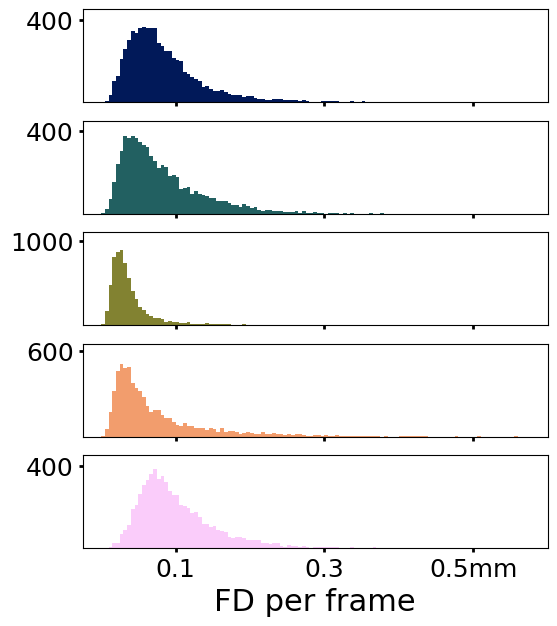

In [7]:
# FD per frame plot

SMALL_SIZE = 3
MEDIUM_SIZE = 18
BIGGER_SIZE = 22

plt.rc('font', size=SMALL_SIZE)  # controls default text sizes
plt.rc('axes', titlesize=BIGGER_SIZE)  # fontsize of the axes title
plt.rc('axes', labelsize=BIGGER_SIZE)  # fontsize of the x and y labels
plt.rc('xtick', labelsize=MEDIUM_SIZE)  # fontsize of the tick labels
plt.rc('ytick', labelsize=MEDIUM_SIZE)  # fontsize of the tick labels
plt.rc('legend', fontsize=SMALL_SIZE)  # legend fontsize
plt.rc('figure', titlesize=BIGGER_SIZE)  # fontsize of the figure title

fig, axes = plt.subplots(5, 1, figsize=(6, 7), sharex=True)

subjects = layout_input.get_subject()

cmap=cm.batlow.resampled(len(subjects))
fd_per_frames = {}

for i, sub in enumerate(subjects):
    raw_data = []
    sub_files = layout_input.get(subject=sub, desc='confounds', suffix='timeseries', extension='tsv')
    
    for except_file in EXCEPT_FILES:
        if except_file['subject'] == sub:
            sub_files = [f for f in sub_files if not (f.entities['session'] == except_file['session'] and f.entities['run'] in except_file['run'])]

    for file in sub_files:
        sub_df = file.get_df().dropna()
        raw_data.append(sub_df['framewise_displacement'].tolist())

    raw_data = np.array(raw_data)

    axes[i].hist(raw_data.reshape(-1), bins=np.arange(0, 0.6, 0.005), color=cmap.colors[i])
    axes[i].set_xlim((-0.025, 0.6))
    axes[i].set_xticks(ticks=[0.1, 0.3, 0.5])
    axes[i].tick_params(width=2, size=3)

    if sub=='03':
        axes[i].set_ylim((0, 1100))
        axes[i].set_yticks(ticks=[1000])
        axes[i].set_yticklabels(['1000'])
    elif sub=='05':
        axes[i].set_ylim((0, 650))
        axes[i].set_yticks(ticks=[600])
        axes[i].set_yticklabels(['600'])
    else:
        axes[i].set_ylim((0, 450))
        axes[i].set_yticks(ticks=[400])
        axes[i].set_yticklabels(['400'])
    
    axes[i].set_xticklabels(['0.1', '0.3', '0.5mm'])
    
    fd_per_frames.update({
        sub: raw_data
    })

plt.xlabel('FD per frame')
plt.savefig(f"{output_path}/fwd_distribution_perFrame.svg", dpi=600, bbox_inches='tight', transparent=True)

### 2.3 | Percentage of frames below thresholds

The code below returns averaged percentage of frames below certain motion thresholds.

To specify different framewise displacement thresholds, you can change the values in the list `thresh`.

In [9]:
thresh = [0.1, 0.2]

for thr in thresh:
    print(f"\nPercentage of frames below {str(thr)}mm")
    tot_frames = np.array([])
    
    for key in fd_per_frames.keys():
        frames_per_sub = fd_per_frames[key].flatten()
        tot_frames = np.hstack((tot_frames, frames_per_sub))

        print(f"sub-{key}: {np.round(np.mean(frames_per_sub<thr) *100, 0)} +/- {np.round(np.std(frames_per_sub<thr) *100, 0)} %")

    print(f"\nTotal percentage of frames: {np.round(np.mean(tot_frames<thr)*100, 0)} +/- {np.round(np.std(tot_frames<thr)*100, 0)} %")



Percentage of frames below 0.1mm
sub-01: 71.0 +/- 46.0 %
sub-02: 72.0 +/- 45.0 %
sub-03: 93.0 +/- 26.0 %
sub-05: 75.0 +/- 43.0 %
sub-06: 58.0 +/- 49.0 %

Total percentage of frames: 74.0 +/- 44.0 %

Percentage of frames below 0.2mm
sub-01: 95.0 +/- 22.0 %
sub-02: 96.0 +/- 20.0 %
sub-03: 98.0 +/- 13.0 %
sub-05: 91.0 +/- 28.0 %
sub-06: 93.0 +/- 26.0 %

Total percentage of frames: 95.0 +/- 22.0 %


---
# 3 | Average Framewise Displacement per run (Figure XX, XX panel)

**Fig. XX (XX)** features the distribution of average framewise displacement per run for each subject.

**Input files**: 
* cneuromod-emotion-videos/emotion-videos/emotion-videos.fmriprep/sub-{sub_num}/ses-{ses-num}/func/sub-{sub_num}_ses-{ses-num}_task-emotion_run-{run-num}_part-mag_desc-confounds_timeseries.tsv

### 3.1 | Set paths and variables

In [10]:
# Same variables instantiated in section 2.1
# You only need to run this cell if you haven't run the one in section 2.1
input_path = Path("../../cneuromod.emotion-videos.fmriprep").resolve()
layout_input = BIDSLayout(input_path, is_derivative=True, validate=False)

output_path = Path('../figures').resolve()
output_path.mkdir(parents=True, exist_ok=True)

### 3.2 | Run the code below to generate Fig. XX (XX)

Some parameters can be changed in the cell below to obtain the distributions for specific subjects:
- `subjects`: list of str (subject id). Currently, all subjects present in `layout_input` are considered. If you want to plot the distribution for a given subject, for example sub-03, you can change the first line to: `subjects = ['03']`

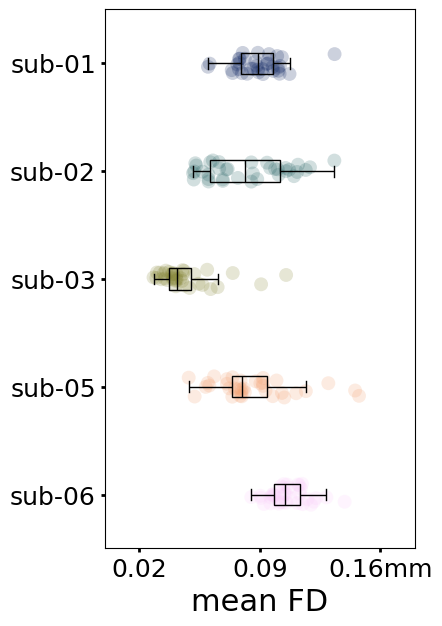

In [11]:
SMALL_SIZE = 3
MEDIUM_SIZE = 18
BIGGER_SIZE = 22

plt.rc('font', size=SMALL_SIZE)  # controls default text sizes
plt.rc('axes', titlesize=BIGGER_SIZE)  # fontsize of the axes title
plt.rc('axes', labelsize=BIGGER_SIZE)  # fontsize of the x and y labels
plt.rc('xtick', labelsize=MEDIUM_SIZE)  # fontsize of the tick labels
plt.rc('ytick', labelsize=MEDIUM_SIZE)  # fontsize of the tick labels
plt.rc('legend', fontsize=SMALL_SIZE)  # legend fontsize
plt.rc('figure', titlesize=BIGGER_SIZE)  # fontsize of the figure title


subjects = layout_input.get_subject()
df = pd.DataFrame()

for i, sub in enumerate(subjects):
    mean_data = []
    session = []
    sub_files = layout_input.get(subject=sub, desc='confounds', suffix='timeseries', extension='tsv')
    
    for except_file in EXCEPT_FILES:
        if except_file['subject'] == sub:
            sub_files = [f for f in sub_files if not (f.entities['session'] == except_file['session'] and f.entities['run'] in except_file['run'])]
    
    for file in sub_files:
        sub_df = file.get_df().dropna()
        mean_data.append(sub_df['framewise_displacement'].mean())
        session.append(file.get_entities()['session'])

    mean_data = np.array(mean_data)

    df = pd.concat(
        [
            df,
            pd.DataFrame({
                'mean_framewise_displacement': mean_data, 
                'subject_id': [f'sub-{sub}']*len(mean_data),
                'session_id': session
            })
        ],
        ignore_index=True
    )

f, ax = plt.subplots(figsize=(4, 7))
dy="subject_id"; dx="mean_framewise_displacement"; ort="h"; 
cmap=sns.color_palette(cm.batlow.resampled(len(subjects)).colors)

ax=sns.stripplot(x = dx, y = dy, data = df, palette = cmap, edgecolor = "white",
                 size = 3, alpha=0.20, s=10, jitter = 0.1, zorder = 0, orient = ort)

ax=sns.boxplot(x = dx, y = dy, data = df, color = "black", width = .20, zorder = 10, 
               showcaps = True, boxprops = {'facecolor':'none', "zorder":10},
               showfliers=False, whiskerprops = {'linewidth':1, "zorder":10},
               saturation = 1, orient = ort)

ax.tick_params(width=2, size=3)

plt.xlim([0, 0.18])
plt.xticks([0.02, 0.09, 0.16], ['0.02', '0.09', '0.16mm'])
plt.xlabel('mean FD')
plt.ylabel('')

plt.savefig(f"{output_path}/fwd_distribution_perRun.svg", dpi=600, bbox_inches='tight', transparent=True)


### 3.3 | Mean FD values per subject

The cell below returns the mean FD values across runs per suject.

In [12]:
df.groupby('subject_id').describe()

mean_framewise_displacement                                \
                                 count      mean       std       min   
subject_id                                                             
sub-01                            36.0  0.088856  0.013638  0.059847   
sub-02                            36.0  0.082331  0.023501  0.051192   
sub-03                            36.0  0.046520  0.016387  0.028241   
sub-05                            36.0  0.085947  0.022989  0.048652   
sub-06                            36.0  0.106577  0.011295  0.085000   

                                                    
                 25%       50%       75%       max  
subject_id                                          
sub-01      0.079276  0.088840  0.097514  0.133358  
sub-02      0.060916  0.081115  0.101889  0.133232  
sub-03      0.037036  0.041577  0.049847  0.105227  
sub-05      0.073551  0.079451  0.094296  0.147557  
sub-06      0.098442  0.104636  0.113275  0.139192

---
# 4 | Average tSNR maps (Figure XX, XX panel)

**Fig. XX (XX)** tSNR spatial maps averaged per subject. The code below generates a figure for each specified slice separately, but were combined afterward using inkscape to create the final figure.

**The tSNR maps were generated using ds_prep scripts using the following workflow:**
1. Compute the tSNR map at the run level
2. Resample the tSNR map to the T1w space
3. Compute the average between the T1w resampled tSNR map across runs for each subject

The tsnr maps were computed for:
 - the second echo images minimally preprocessed (\*echo-2\*bold.nii.gz; fMRIPrep outputs)
 - the optimally combined images (\*desc-optcom_bold.nii.gz; tedana outputs)
 - the denoised optimally combined images (\*desc-denoised_bold.nii.gz; tedana outputs).

**Input files**: 
All files can be found in `cneuromod-emotion-videos/emotion-videos/emotion-videos.tsnr`:
* Echo 2: sub-{sub_num}/sub-{sub_num}_task-emotion_space-T1w_echo-2_stat-avgtsnr_desc-preproc_statmap.nii.gz
* Optimally combined: sub-{sub_num}/sub-{sub_num}_task-emotion_space-T1w_stat-avgtsnr_desc-optcom_statmap.nii.gz
* Denoised optimally combined: sub-{sub_num}/sub-{sub_num}_task-emotion_space-T1w_stat-avgtsnr_desc-denoised_statmap.nii.gz



### 4.1 | Set paths and variables

In [23]:
input_path = Path("../../emotion-videos.tsnr").resolve()
layout_input = BIDSLayout(input_path, is_derivative=True, validate=False)

fmriprep_path = Path("../../cneuromod.emotion-videos.fmriprep").resolve()
layout_fmriprep = BIDSLayout(fmriprep_path, is_derivative=True, validate=False)

output_path = Path('../figures/tsnr').resolve()

### 4.2 |  Run the code below to generate Fig. XX (XX)

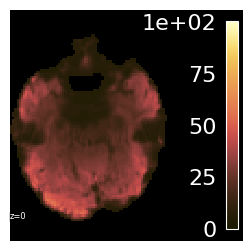

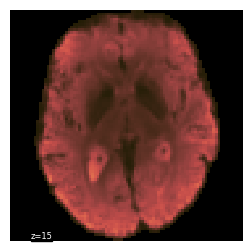

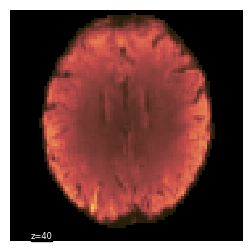

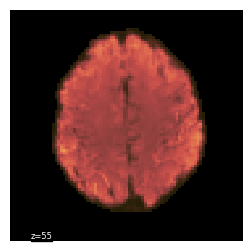

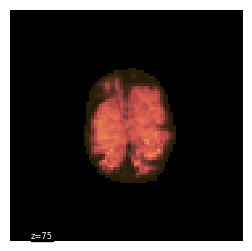

In [24]:
subjects = layout_input.get_subjects()

coords_to_plot = {
    '01': {'z': [0, 15, 40, 55, 75]},
    '02': {'z': [-40, 0, 15, 30, 50]},
    '03': {'z': [-20, 0, 20, 40, 60]},
    '05': {'z': [-14, 16, 34, 50, 72]},
    '06': {'z': [-15, 10, 34, 50, 66]},
}

tsnr_type = ['preproc', 'optcom', 'denoised']

labelfontsize = 7
ticksfontsize = np.round(labelfontsize*0.8)

for subject in subjects[:1]:
    
    for tsnr_t in tsnr_type[:1]:
        # Retrieve the map
        tsnr_map = [f for f in layout_input.get(subject=subject, space='T1w', desc=tsnr_t, suffix='statmap', extension='.nii.gz') if 'stat-avgtsnr' in f.filename]
        
        if len(tsnr_map)==0:
            raise IOError(f"No tSNR map associated with {tsnr_t} for sub-{subject}")
        elif len(tsnr_map)>1:
            raise IOError(f"More than one tSNR map associated with {tnsr_t} for sub-{subject}")
        else:
            tsnr_map = tsnr_map[0]
            
        entities = tsnr_map.get_entities()
        
        # Retrieve mask
        mask = layout_fmriprep.get(subject=subject, part='mag', space='T1w', desc='brain', suffix='mask', extension='.nii.gz')
        mask = mask[0]
        
        # Apply mask on tSNR map
        tsnr_map_masked = unmask(apply_mask(tsnr_map.path, mask.path), mask.path)
        
        for axis, coord in coords_to_plot[subject].items():
            for idx, c in enumerate(coord):
                fig, ax = plt.subplots(figsize=(3, 3))
                
                # Only plot the colorbar for the first coordinate
                if idx==0:
                    plot_colorbar=True 
                else:
                    plot_colorbar=False
                    
                disp = plotting.plot_stat_map(
                    tsnr_map_masked,
                    bg_img=mask.path,
                    cmap=cm.lajolla,
                    threshold=0,
                    draw_cross=False,
                    annotate=False,
                    axes=ax,
                    vmax=100,
                    display_mode=axis,
                    cut_coords=(c,),
                    colorbar=plot_colorbar
                )
                
                disp.annotate(size=ticksfontsize, left_right=False)
                
                pattern='sub-{subject}_task-{task}_space-{space}[_echo-{echo}]_stat-avgtsnr_coord-coord_desc-{desc}_statmap.svg'
                file_out = layout_input.build_path(entities, pattern, validate=False).replace(str(input_path), str(Path(output_path, f'sub-{subject}'))).replace('coord-coord', f'coord-{axis}{c}')
                Path(file_out).parent.mkdir(parents=True, exist_ok=True)
                
                fig.savefig(
                    file_out,
                    transparent=True,
                    dpi=600,
                    bbox_inches='tight'
                )


---
# 5 | tSNR distributions (Figures XX, XX panel)

**Fig. XX (XX)** and **Fig. XX (XX)** voxelwise tSNR distributions aggregated across all runs for each subject. 

**The tSNR maps were generated using the following workflow:**
1. Compute the tSNR map at the run level
2. Resample the tSNR map to the T1w space
3. Compute the average between the T1w resampled tSNR map across runs for each subject

The tsnr maps were computed for:
 - the second echo images minimally preprocessed (\*echo-2\*bold.nii.gz; fMRIPrep outputs)
 - the optimally combined images (\*desc-optcom_bold.nii.gz; tedana outputs)
 - the denoised optimally combined images (\*desc-denoised_bold.nii.gz; tedana outputs).

**Input files**: 
All files can be found in `cneuromod-emotion-videos/emotion-videos/emotion-videos.tsnr`:
* Echo 2: sub-{sub_num}/sub-{sub_num}_task-emotion_space-T1w_echo-2_stat-avgtsnr_desc-preproc_statmap.nii.gz
* Optimally combined: sub-{sub_num}/sub-{sub_num}_task-emotion_space-T1w_stat-avgtsnr_desc-optcom_statmap.nii.gz
* Denoised optimally combined: sub-{sub_num}/sub-{sub_num}_task-emotion_space-T1w_stat-avgtsnr_desc-denoised_statmap.nii.gz

**Code availability:**
<br>The code used to generate the input files to create this figure can be found in the [courtois-neuromod ds_prep repository](https://github.com/courtois-neuromod/ds_prep)


### 5.1 | Set paths and variables

In [20]:
input_path = Path("../../emotion-videos.tsnr").resolve()
layout_input = BIDSLayout(input_path, is_derivative=True, validate=False)

fmriprep_path = Path("../../cneuromod.emotion-videos.fmriprep").resolve()
layout_fmriprep = BIDSLayout(fmriprep_path, is_derivative=True, validate=False)

output_path = Path('../figures/tsnr').resolve()

### 5.2 |  Run the code below to generate Fig. XX (XX)

The code below generates the voxelwise distributions at the whole-brain level using the MNI152NLin2009cAsym brain mask (res-02) fetched from [templateflow](https://www.templateflow.org/browse/).

Some parameters can be changed in the cell below to obtain the distributions for different ROIs, specific subjects or specifics tSNR maps:
- `subjects`: list of str (subject id). Currently, all subjects present in `layout_input` are considered. If you want to plot the distribution for a given subject, for example sub-03, you can change the first line to: `subjects = ['03']`
  
- `tsnr_type`: list of str defining which tSNR files to take into account for plotting. Can be either 'preproc' (tSNR map generated from the echo-2 image in the fmriprep submodule), 'optcom' (tSNR map generated from the optimally combined image in the tedana submodule) or 'denoised' (tSNR map generated from the denoised optimally combined image in the tedana submodule). For example, if you only want to plot the distributions related to the tSNR maps generated from the tedana outputs only, you can specify: `tsnr_type = ['optcom', 'denoised']`


sub-01
              value                                                        \
              count       mean        std       min        25%        50%   
type                                                                        
denoised  8490240.0  58.398795  21.926257  0.000000  43.796483  58.560881   
optcom    8490240.0  45.678500  16.791540  0.000000  34.838313  46.891459   
preproc   8490240.0  30.825908  12.306474  1.429354  22.669462  31.660545   

                                 
                75%         max  
type                             
denoised  72.935860  201.430817  
optcom    57.292741  139.921982  
preproc   39.228367  103.163483  

sub-02
              value                                                   \
              count       mean        std  min        25%        50%   
type                                                                   
denoised  8490240.0  47.952813  19.892936  0.0  33.442948  46.923586   
optcom    8490240.0  41.42319

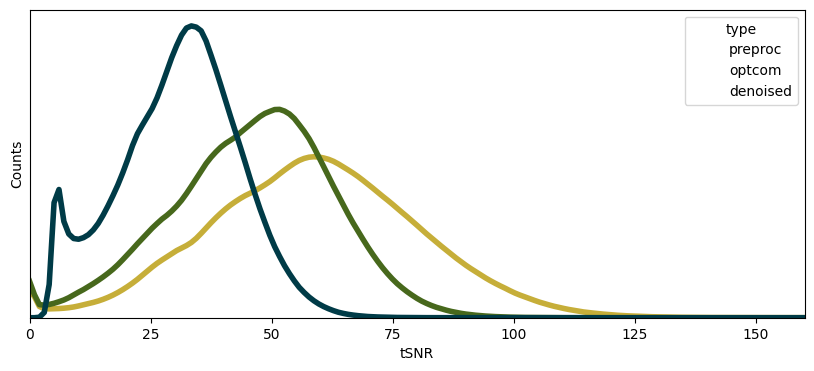

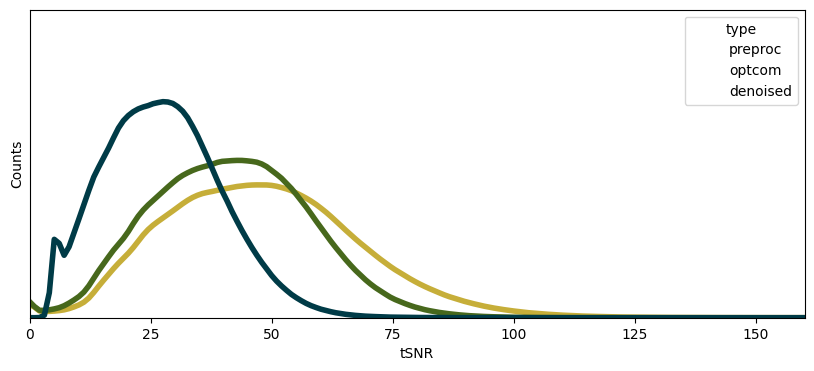

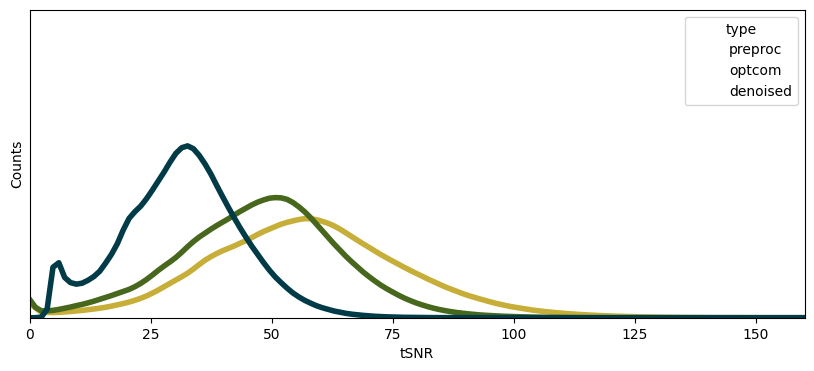

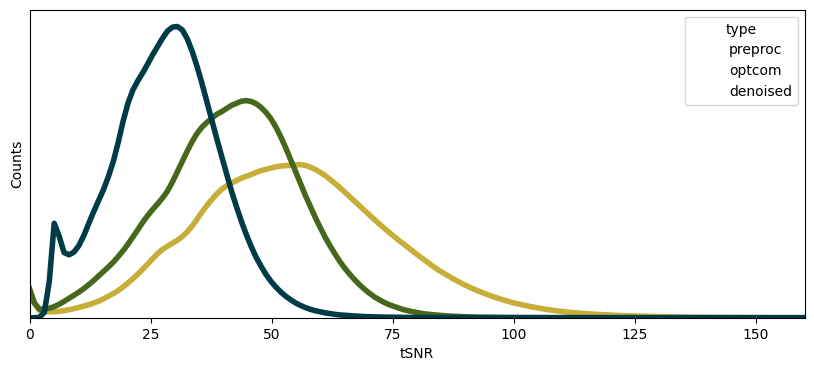

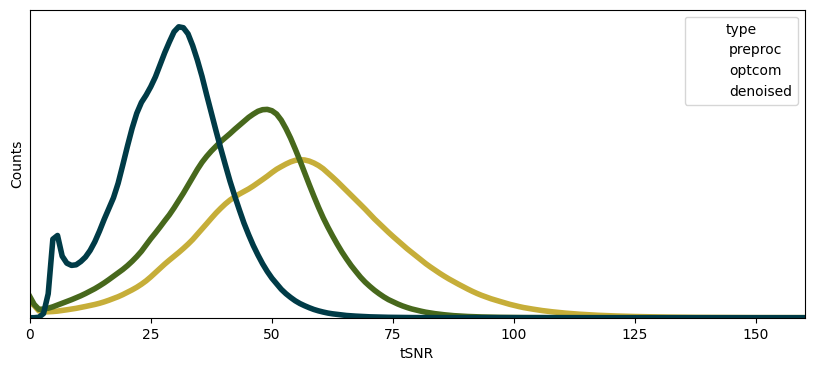

In [25]:
subjects = layout_input.get_subjects()

tsnr_type = ['preproc', 'optcom', 'denoised']

labelfontsize = 7
ticksfontsize = np.round(labelfontsize*0.8)

cmap=sns.color_palette(cm.bamako.resampled(6).colors)
cmap=sns.color_palette(np.array([cmap[0], cmap[2], cmap[4]]))

for subject in subjects:
    print(f'\nsub-{subject}')
    tsnr_values_per_type = pd.DataFrame()
    
    for tsnr_t in tsnr_type:
        tsnr_values = np.array([])
        
        # Retrieve the map
        tsnr_maps = [f for f in layout_input.get(subject=subject, space='MNI152NLin2009cAsym', desc=tsnr_t, suffix='statmap', extension='.nii.gz') if 'stat-avgtsnr' not in f.filename]
        
        for except_file in EXCEPT_FILES:
            if except_file['subject'] == subject:
                tsnr_maps = [f for f in tsnr_maps if not (f.entities['session'] == except_file['session'] and f.entities['run'] in except_file['run'])]
        
        # Retrieve mask
        mask = tf.get('MNI152NLin2009cAsym', desc='brain', suffix='mask')
        mask = [m for m in mask if 'res-02' in m.name]
        mask = resample_to_img(mask, tsnr_maps[0].path, interpolation="nearest")        

        # Extract voxel-wise tSNR values for each run
        for tsnr_map in tsnr_maps:
            
            tsnr_map_masked = apply_mask(tsnr_map.path, mask)
            tsnr_values = np.concatenate((tsnr_values, tsnr_map_masked), axis=0)
            
        tsnr_values_per_type = pd.concat(
            [tsnr_values_per_type, pd.DataFrame({'value': tsnr_values, 'type': [tsnr_t]*len(tsnr_values)})],
            axis=0
        )
    
    print(tsnr_values_per_type.groupby('type').describe())

    # Plot figure
    plt.figure(figsize=(10, 4))

    ax = sns.histplot(
        data=tsnr_values_per_type,
        x='value',
        kde=True,
        stat='count',
        alpha=0,
        hue='type',
        fill=False,
        line_kws={'lw':4},
        palette=cmap
    )
    
    for line in ax.lines:
        line.set_rasterized(True)

    plt.xlim([0, 160])
    plt.xticks([0, 25, 50, 75, 100, 125, 150], ['0', '25', '50', '75', '100', '125', '150'])
    plt.yticks([])
    if subject =='02':
        plt.ylim([0, 65000])
    if subject =='03':
        plt.ylim([0, 100000])
    plt.ylabel('Counts')
    plt.xlabel('tSNR')

    Path(f"{output_path}/sub-{subject}/").mkdir(parents=True, exist_ok=True)
    
    plt.savefig(f"{output_path}/sub-{subject}/sub-{subject}_task-emotion_space-MNI152NLin2009cAsym_stat-avgtsnr_desc-brainCounts_distribution.svg", dpi=200, bbox_inches='tight', transparent=True)
    

### 5.3 |  Run the code below to generate Fig. XX (XX)

The code below generates the voxelwise distributions for specific regions of interest (ROIs). Those ROIs were taken from the [Harvard Oxford atlas fetched from nilearn](https://nilearn.github.io/dev/modules/generated/nilearn.datasets.fetch_atlas_harvard_oxford.html#nilearn.datasets.fetch_atlas_harvard_oxford). 

Some parameters can be changed in the cell below to obtain the distributions for different ROIs, specific subjects or specifics tSNR maps:
- `subjects`: list of str (subject id). Currently, all subjects present in `layout_input` are considered. If you want to plot the distribution for a given subject, for example sub-03, you can change the first line to: `subjects = ['03']`
- `roi_names`: list of dictionaries containing the label of the ROI from which to extract the voxelwise tSNR values, and the abbreviation for that ROI (for filenaming purposes only; can be anything you'd like). The value associated with the key 'label' should match the labels in the Harvard Oxford atlas. To know which label values are valid, you can follow those instructions:

    ```python
    # Fetch the altas
    atlas = fetch_atlas_harvard_oxford('cort-maxprob-thr25-2mm')
    # Print the labels
    print(atlas.labels)

    
- `tsnr_type`: list of str defining which tSNR files to take into account for plotting. Can be either 'preproc' (tSNR map generated from the echo-2 image in the fmriprep submodule), 'optcom' (tSNR map generated from the optimally combined image in the tedana submodule) or 'denoised' (tSNR map generated from the denoised optimally combined image in the tedana submodule). For example, if you only want to plot the distributions related to the tSNR maps generated from the tedana outputs only, you can specify: `tsnr_type = ['optcom', 'denoised']`

[fetch_atlas_harvard_oxford] Dataset found in /home/user/nilearn_data/fsl
sub-01
             value                                                   \
             count       mean        std  min        25%        50%   
type                                                                  
denoised  554292.0  67.933562  24.870762  0.0  52.320734  69.343494   
optcom    554292.0  44.694353  18.865356  0.0  30.972067  45.290142   
preproc   554292.0  30.090077  16.894549  0.0  16.397060  32.826654   

                                 
                75%         max  
type                             
denoised  85.540680  165.799881  
optcom    58.355824  120.986656  
preproc   43.359065   90.459030  
sub-02
             value                                                   \
             count       mean        std  min        25%        50%   
type                                                                  
denoised  554292.0  60.923180  21.836727  0.0  47.241477  61.903912 

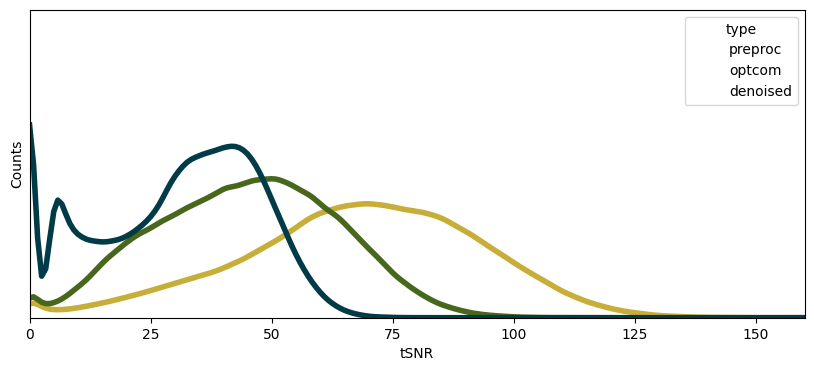

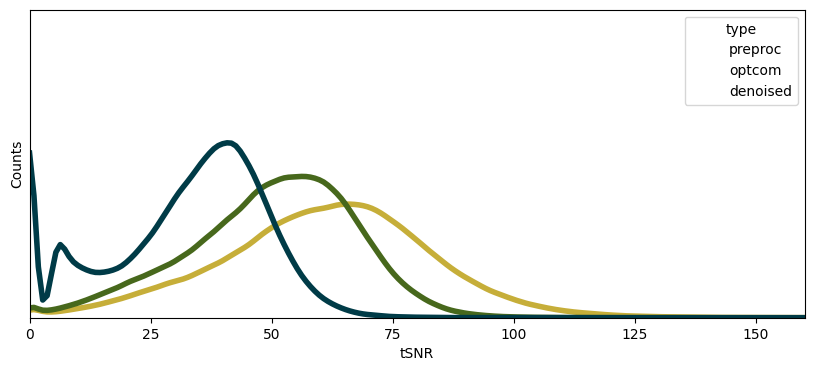

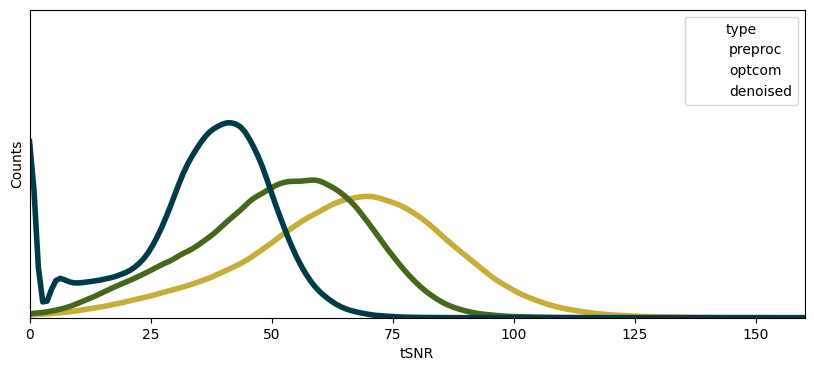

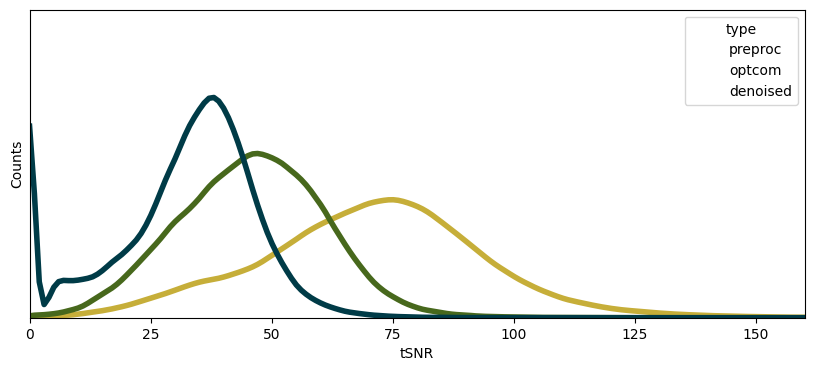

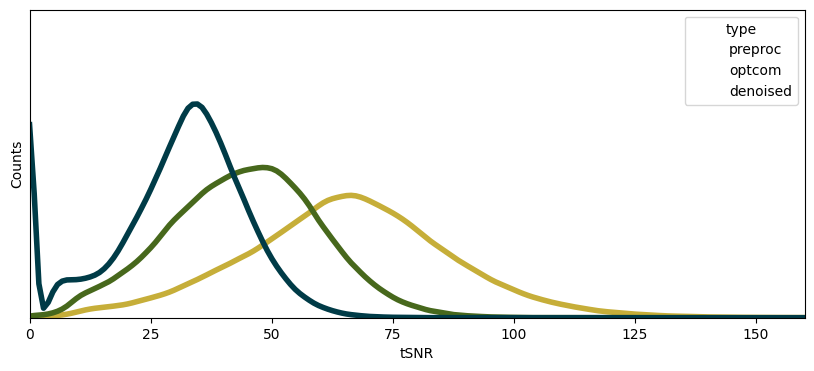

In [21]:
subjects = layout_input.get_subjects()
roi_names = [{'label': 'Frontal Pole', 'abbrev': 'FP'}, {'label': 'Frontal Orbital Cortex', 'abbrev': 'OFC'}]

# ---
# Define ROI
atlas = fetch_atlas_harvard_oxford('cort-maxprob-thr25-2mm')

atlas_img = atlas.maps
labels = atlas.labels

roi_indices = [labels.index(roi_name['label']) for roi_name in roi_names]
roi_masks = [math_img("img == %d" % roi_index, img=atlas_img) for roi_index in roi_indices]
# ---

tsnr_type = ['preproc', 'optcom', 'denoised']

labelfontsize = 7
ticksfontsize = np.round(labelfontsize*0.8)

cmap=sns.color_palette(cm.bamako.resampled(6).colors)
cmap=sns.color_palette(np.array([cmap[0], cmap[2], cmap[4]]))

for subject in subjects:
    print(f'sub-{subject}')
    tsnr_values_per_type = pd.DataFrame()
    sub_tmp_masked = []
    
    for roi_name, roi_mask in zip(roi_names, roi_masks):
        print(roi_name)
        for tsnr_t in tsnr_type:
            tsnr_values = np.array([])
            tmp_masked = []

            # Retrieve the map
            tsnr_maps = [f for f in layout_input.get(subject=subject, space='MNI152NLin2009cAsym', desc=tsnr_t, suffix='statmap', extension='.nii.gz') if 'stat-avgtsnr' not in f.filename]

            for except_file in EXCEPT_FILES:
                if except_file['subject'] == subject:
                    tsnr_maps = [f for f in tsnr_maps if not (f.entities['session'] == except_file['session'] and f.entities['run'] in except_file['run'])]

            # Extract voxel-wise tSNR values for each run
            for tsnr_map in tsnr_maps:
                # Apply mask
                roi_resampled = resample_to_img(roi_mask, tsnr_map.path, interpolation="nearest")
                masker = NiftiMasker(mask_img=roi_resampled, standardize=False)
                
                tsnr_map_masked = masker.fit_transform(tsnr_map.path)

                tmp_masked.append(masker.inverse_transform(tsnr_map_masked))    
                tsnr_values = np.concatenate((tsnr_values, tsnr_map_masked), axis=0)

            tsnr_values_per_type = pd.concat(
                [tsnr_values_per_type, pd.DataFrame({'value': tsnr_values, 'type': [tsnr_t]*len(tsnr_values)})],
                axis=0
            )

        print(tsnr_values_per_type.groupby('type').describe())

        # Plot figure
        plt.figure(figsize=(10, 4))

        sns.histplot(
            data=tsnr_values_per_type,
            x='value',
            kde=True,
            stat='count',
            alpha=0,
            hue='type',
            fill=False,
            line_kws={'lw':4},
            palette=cmap,
            rasterized=True
        )

        plt.xlim([0, 160])
        plt.xticks([0, 25, 50, 75, 100, 125, 150], ['0', '25', '50', '75', '100', '125', '150'])
        plt.ylim([0, 14000])
        plt.yticks([])

        plt.ylabel('Counts')
        plt.xlabel('tSNR')

        Path(f"{output_path}/sub-{subject}/").mkdir(parents=True, exist_ok=True)
        
        plt.savefig(
            f"{output_path}/sub-{subject}/sub-{subject}_task-emotion_space-MNI152NLin2009cAsym_stat-avgtsnr_desc-{roi_name['abbrev']}Counts_distribution.svg", 
            dpi=200, 
            bbox_inches='tight', 
            transparent=True
        )
        
        # Plot ROI
        if not os.path.isfile(f"{output_path}/mask-{roi_name['abbrev']}.svg"):
            plotting.plot_roi(
                roi_mask,
                draw_cross=False, 
                annotate=False,
                output_file=f"{output_path}/mask-{roi_name['abbrev']}.svg"
            )

---
# 6 | Subject-level GLM maps (Figures XX, XX panel)

**Fig. XX (XX)** and **Fig. XX (XX)** showing the activity related to the presentation of the stimuli and to normative affective ratings.

**The statistical maps were generated using custom python scripts using nilearn. The following workflow was used for each subject :**

*Brain activity related to the presentation of stimuli*
1. Fit a GLM for each run: only one regressor specifying the onset and duration of the stimuli is specified. No confounding variables were added since they were used in Tedana for ICA components selection.
2. Extract the activation related to stimulus presentation using the regressor at the run-level.
3. Perform a one sample t-test at the subject-level using the run-level contrasts.

*Brain activity correlated with normative valence and arousal ratings*
1. Fit a GLM for each run: the normative valence and arousal ratings were specified as parameteric modulators in the design matrix. The interaction between the valence and arousal was also accounted for. All parametric regressors were separated by positive (>=5; n=1194) and negative valence (<5; n=694).
2. Extract the activation related to each regressors at the run-level.
3. Perform a one sample t-test at the subject-level using the run-level contrasts.

**Motivation:**
<br>The first contrast was used as a sanity check to make sure we were observing activations in expected areas related to the stimuli presentation. 
<br>The second contrast was used to make sure that brain activations correlated with the normative valence and arousal ratings acquired on an independent sample (see [Cowen & Keltner, 2017](https://doi.org/10.1073/pnas.1702247114)).

**Input files**: 
- All contrast files can be found in subject-specific folder in the `cneuromod-emotion-videos/emotion-videos/emotion-videos.glm` subdirectory.
- The atlas used to segment voxels into brain networks can be found in the `anat.atlases/` subdirectory.


**Code availability:**
<br>The code used to generate the input contrast files to create this figure can be found under: `cneuromod-emotion-videos/emotion-videos/emotion-videos.glm/code/glm.py`

### 6.1 | Set paths and variables

In [6]:
input_path = Path("../../emotion-videos.glm").resolve()
layout_input = BIDSLayout(input_path, is_derivative=True, validate=False)

atlas_path = Path('../anat.atlases/tpl-MNI152NLin2009cAsym/tpl-MNI152NLin2009cAsym_res-01_atlas-Schaefer2018TianS3NettekovenAsym_desc-1000Parcels7Networks50Subcort128Cereb_dseg.nii.gz')
atlas_labels = pd.read_csv(
    '../anat.atlases/tpl-MNI152NLin2009cAsym/tpl-MNI152NLin2009cAsym_atlas-Schaefer2018TianS3NettekovenAsym_desc-1000Parcels7Networks50Subcort128Cereb.tsv',
    sep='\t'
)

output_path = Path('../figures/glm').resolve()

In [7]:
networks = {
    'Default': {
        'abbrev':'DMN',
        'label': 'defaultMode'
    },
    'DorsAttn': {
        'abbrev': 'DAN',
        'label': 'dorsalAttention'
    },
    'Cont': {
        'abbrev': 'FPN',
        'label': 'frontoParietal'
    },
    'Limbic': {
        'abbrev': 'LN',
        'label': None
    },
    'SomMot': {
        'abbrev': 'SMN',
        'label': 'sensorimotor'
    },
    'SalVentAttn': {
        'abbrev': 'VAN',
        'label': 'ventralAttention'
    },
    'Vis': {
        'abbrev': 'VN',
        'label': 'visual'
    }
}

In [8]:
def extract_beta_estimates(file, stat_type, path_atlas, networks, subject=None, atlas_labels=None, effect_size=True):
    df_effect=pd.DataFrame()
    df_wilcoxon=pd.DataFrame()
    
    path_atlas = Path(path_atlas)
    
    if path_atlas.is_file():
        is_file=True
    else:
        is_file=False
        
    # Extract beta estimates per network
    for network in networks.keys():
        if is_file:
            if atlas_labels is None:
                raise ValueError("Please provide dataframe mapping each parcel to a network")
            
            regions=atlas_labels.loc[atlas_labels['name'].str.contains(network, na=False), 'index'].tolist()
            network_mask = math_img(f"np.isin(img, {regions}).astype(int)", img=path_atlas)
            network_mask = resample_to_img(network_mask, file, interpolation='nearest')
        else:
            if subject is None:
                raise ValueError("Please specify subject id to retrieve specific mask")
            
            if networks[network]['label'] is None:
                print(f'No label associated with {network}')
                continue
            else:
                network_mask = [os.path.join(path_atlas, f) for f in os.listdir(path_atlas) if f'sub-{subject}' in f and networks[network]['label'] in f]

            if len (network_mask) != 1:
                print(f'Mask(s) found: {network_mask}')
                raise IOError('No mask found or more than one mask found. See above.')
            
            network_mask = network_mask[0]
            
        data = NiftiMasker(network_mask).fit_transform(file)
        df_effect = pd.concat([df_effect, pd.DataFrame({'network': [network]*len(data), stat_type: data})], axis=0)
    
        if effect_size:
            # Compute Wilcoxon test with effect size
            stat_test = wilcoxon(data, y=0, alternative='two-sided')
            stat_test['network'] = network

            df_wilcoxon = pd.concat([df_wilcoxon, stat_test])
            df_wilcoxon = df_wilcoxon.reset_index(drop=True)
    
    return df_effect, df_wilcoxon, network_mask

In [11]:
def plot_beta_estimates(df, stat_type, subject, xlim, networks):
        np.random.seed(42)
        
        # Define specific figure parameters
        dx, dy = stat_type, 'network'
        ort='h'
        network_order = df[dy].unique().tolist()
        cmap=sns.color_palette(cm.bamako.resampled(len(network_order)).colors)

        # Instantiate plot
        f, ax = plt.subplots(figsize=(5.2, 5))

        
        ax.axvline(0, color='gray', zorder=0, alpha=0.4)
        
        ax=sns.stripplot(x = dx, y = dy, data = df, palette = cmap, edgecolor = "white",
                     size = 1, alpha=0.70, s=1.5, jitter = 0.08, orient = ort, order=network_order, rasterized=True)

        ax=sns.boxplot(x = dx, y = dy, data = df, color = "black", width = .20, zorder = 10, 
                       showcaps = True, boxprops = {'facecolor':'none', "zorder":10},
                       showfliers=False, whiskerprops = {'linewidth':2, "zorder":10},
                       saturation = 1, orient = ort, order=network_order)
        
        ax=pt.half_violinplot(x = dx, y = dy, data = df, bw = .2, cut = 0., palette=cmap, linewidth=0.5, 
                              scale = "area", width = 1.2, inner = None, orient = ort, order=network_order)

        
        ax.set_xlim(xlim)
        ax.set_ylabel(f'sub-{subject}')
        ymin, ymax = ax.get_ylim()
        ax.set_ylim(ymin, ymax - 0.3)
        # Change y ticks labels
        yticks_labels = ax.get_yticklabels()
        for l in yticks_labels:
            l.set_text(networks[l.get_text()]['abbrev'])
        ax.set_yticklabels(yticks_labels)
        
        plt.tight_layout()
        
        return f

In [12]:
def plot_effect_size(df, networks):
    # Order networks
    df = df.sort_values(by=['network', 'subject'], key=lambda x: x.map({'Default': 6, 'DorsAttn': 5, 'Cont': 4, 'Limbic': 3, 'SomMot': 2, 'SalVentAttn': 1, 'Vis': 0}) if x.name =='network' else x)
    
    # Instantiate plot
    f, ax = plt.subplots(figsize=(10, 6))
    
    ax.grid(True, which='both', alpha=0.6)

    scatter = ax.scatter(
        df['subject'], 
        df['network'], 
        s=np.abs(df['RBC']) * 800, 
        c=df['RBC'], 
        cmap=cm.vik,
        vmin=-1,
        vmax=1, 
        edgecolors='gray',
        linewidth=0.75,
        zorder=2
    )
    
    ax.tick_params(axis='x', rotation=45)
    
    # Change y ticks labels
    yticks_labels = ax.get_yticklabels()
    for l in yticks_labels:
        l.set_text(networks[l.get_text()]['abbrev'])
    ax.set_yticklabels(yticks_labels)
    
    cbar = f.colorbar(scatter, ax=ax, pad=0.02, aspect=20)

    handles, labels = [], []
    for sz in [0.25, 0.50, 0.75, 1.00]:
        handle = ax.scatter([], [], c='darkgray', alpha=0.6, s=sz*800, edgecolors='black', linewidth=0.5)
        handles.append(handle)
        labels.append(f'{sz:.2f}')

    ax.legend(
        handles, labels, 
        title="|Effect Size|", 
        loc='center left', 
        bbox_to_anchor=(1.15, 0.8),
        fontsize=16
    )
    
    return f

### 6.2 |  Run the code below to generate Fig. XX (XX)

The code below generates statistical maps per subject contrasting the activity during the stimuli presentation compared to the inter-trial interval periods.

Some parameters can be changed in the cell below to obtain the maps for specific subjects, specific input types or specific contrast type:
- `subjects`: list of str (subject id). Currently, all subjects present in `layout_input` are considered. If you want to plot the maps for a given subject, for example sub-03, you can change the first line to: `subjects = ['03']`
- `desc`: list of str defining the input type to plot. Can be either 'denoised' and/or 'optcom' to use the statistical maps generated from the denoised optimally combined images or the optimally combined images in the tedana submodule, respectively.
- `contrast_type`: str defining the contrast to plot. Can be either, 'Stim', 'arousal', 'positiveValence', 'negativeValence'. Other contrast related to the continuous regressors (normative ratings) can be used, but the contrast listed are the ones reported in the manuscript. For the exhaustive list of possible contrasts, please look at the available files in the `emotion-videos.glm` submodule.

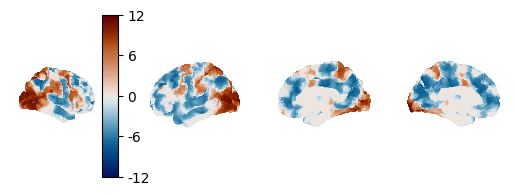

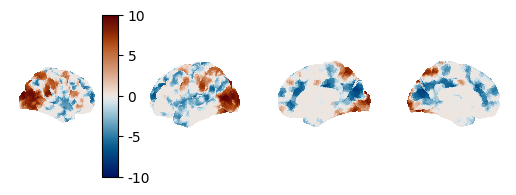

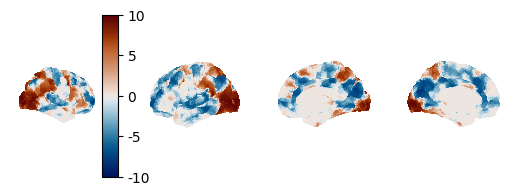

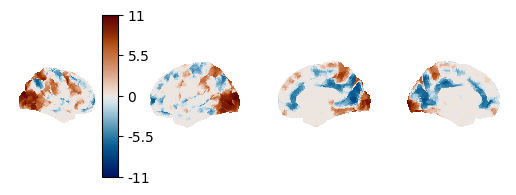

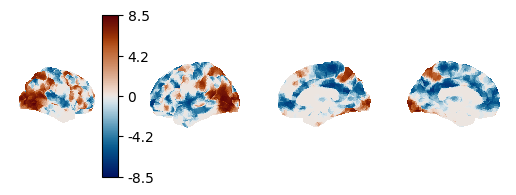

In [19]:
subjects = layout_input.get_subjects()
desc = ['denoised']
contrast_type = 'Stim'

fsaverage5 = load_fsaverage()
fsaverage_data = load_fsaverage_data(data_type="sulcal")

views = {
    'lR': {'hemi': 'right', 'view': 'lateral'},
    'lL': {'hemi': 'left', 'view': 'lateral'},
    'mR': {'hemi': 'right', 'view': 'medial'},
    'mL': {'hemi': 'left', 'view': 'medial'}
}

cbar_range = {
    '01': [-12, 12],
    '02': [-10, 10],
    '03': [-10, 10],
    '05': [-11, 11],
    '06': [-8.5, 8.5],
}

for subject in subjects:
    for d in desc:
        contrast_map = layout_input.get(subject=subject, desc=f'{d}rfx', suffix='statmap', extension='.nii.gz')
        contrast_map = [c for c in contrast_map if 'stat-z' in c.filename and contrast_type in c.filename]
        
        if len(contrast_map)==0:
            raise IOError(f"No contrast map found for sub-{subject}")
            continue
        elif len(contrast_map)>1:
            raise IOError(f"More than one contrast map found for sub-{subject}")
            continue
        else:
            contrast_map = contrast_map[0]
        
        # Apply fdr correction on map
        contrast_map, threshold = threshold_stats_img(
            contrast_map.path,
            alpha=0.001,
            height_control='fdr'
        )
        
        fig, ax = plt.subplots(nrows=1, ncols=4, subplot_kw={'projection': '3d'})
        
        for idx, v in enumerate(views.keys()):
            if idx!=0:
                colorbar=False
            else:
                colorbar=True
                
            plotting.plot_surf_stat_map(
                stat_map=SurfaceImage.from_volume(fsaverage5['pial'], volume_img=contrast_map),
                bg_map=fsaverage_data,
                axes=ax[idx],
                view=views[v]['view'],
                hemi=views[v]['hemi'],
                vmin=cbar_range[subject][0],
                vmax=cbar_range[subject][1],
                colorbar=colorbar,
                cmap=cm.vik
            )
        
        for single_ax in ax:
            for collection in single_ax.collections:
                collection.set_rasterized(True)

        Path(f"{output_path}/sub-{subject}/").mkdir(parents=True, exist_ok=True)
        
        fig.savefig(
            os.path.join(
                output_path,
                f'sub-{subject}',
                f'sub-{subject}_contrast-{contrast_type}_desc-{d}rfx_3dview.svg'
            ),
            dpi=600, bbox_inches='tight', transparent=True
        )

### 6.3 |  Run the code below to generate Fig. XX (XX)

The code below generates the beta estimates distribution per network for each subject, as well as the effect size derived from a Wilcoxon test comparing those distributions against zero.

Some parameters can be changed in the cell below to obtain the maps for specific subjects, specific input types or specific contrast type:
- `subjects`: list of str (subject id). Currently, all subjects present in `layout_input` are considered. If you want to plot the distributions for a given subject, for example sub-03, you can change the first line to: `subjects = ['03']`
- `contrast_type`: str defining the contrast to plot. Can be either, 'Stim', 'arousal', 'positiveValence', 'negativeValence'. Other contrast related to the continuous regressors (normative ratings) can be used, but the contrast listed are the ones reported in the manuscript. For the exhaustive list of possible contrasts, please look at the available files in the `emotion-videos.glm` submodule.

sub-01
    ... Contrast: Stim
    ... Global mean: 0.04631560676117443
    ... Corrected p values on the Wilcoxon tests
       network           pval      pval corr  rejected
0      Default   0.000000e+00   0.000000e+00      True
1     DorsAttn   0.000000e+00   0.000000e+00      True
2         Cont   0.000000e+00   0.000000e+00      True
3       Limbic   0.000000e+00   0.000000e+00      True
4       SomMot   0.000000e+00   0.000000e+00      True
5  SalVentAttn  1.053475e-114  7.374324e-114      True
6          Vis   0.000000e+00   0.000000e+00      True


    ... Contrast: arousal
    ... Global mean: 0.01419000991010102
    ... Corrected p values on the Wilcoxon tests
       network          pval     pval corr  rejected
0      Default  0.000000e+00  0.000000e+00      True
1     DorsAttn  0.000000e+00  0.000000e+00      True
2         Cont  0.000000e+00  0.000000e+00      True
3       Limbic  0.000000e+00  0.000000e+00      True
4       SomMot  0.000000e+00  0.000000e+00      True
5  S

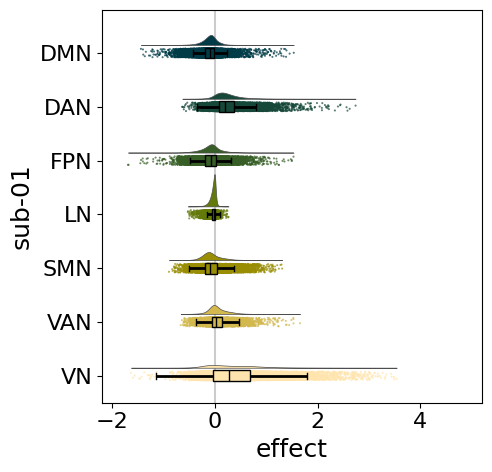

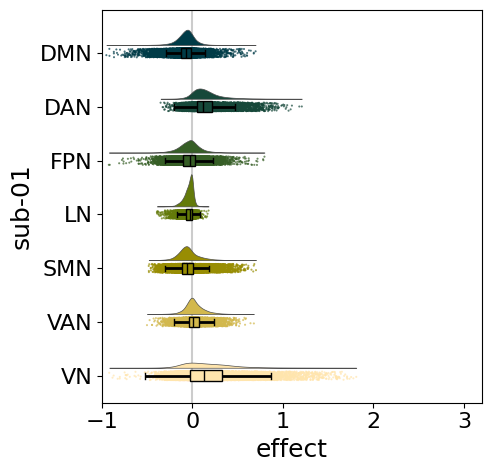

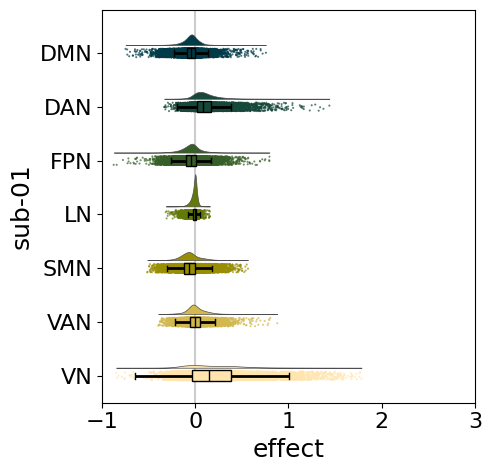

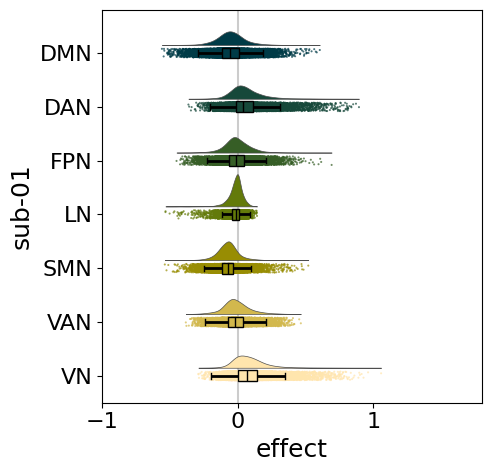

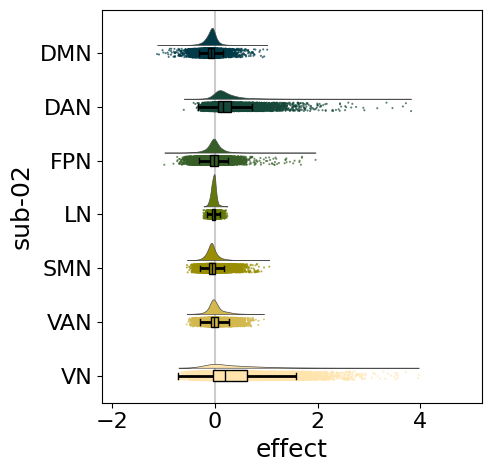

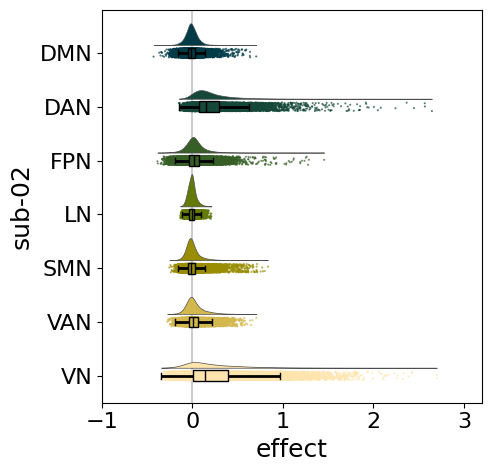

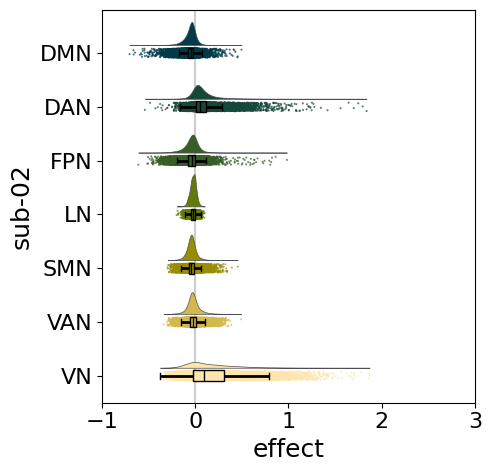

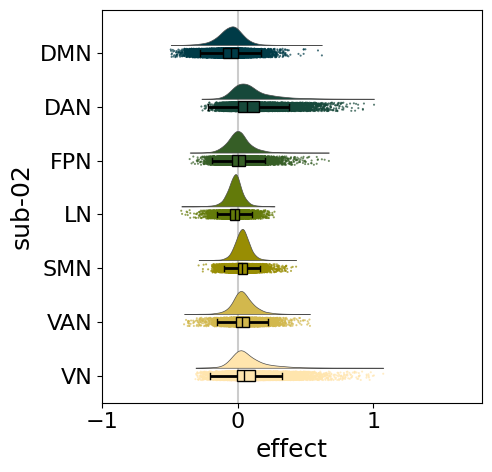

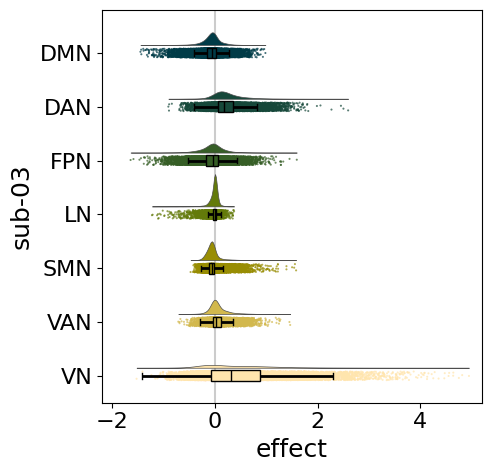

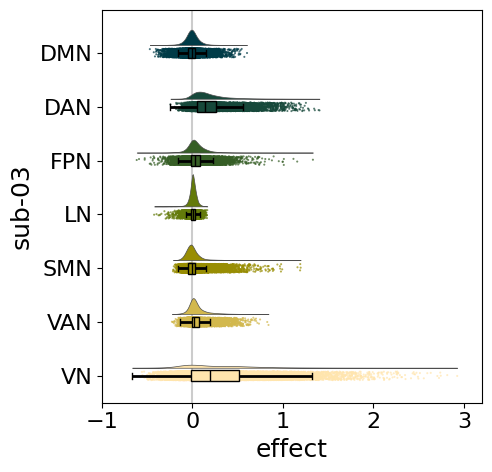

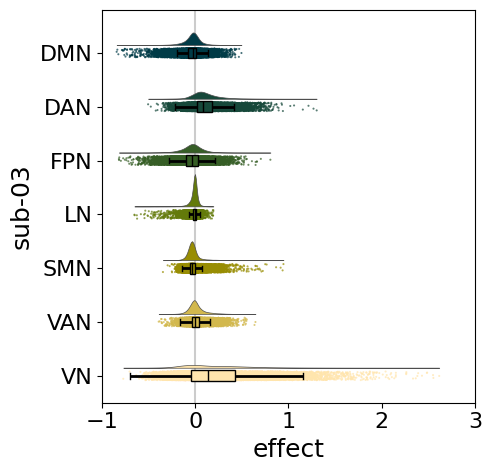

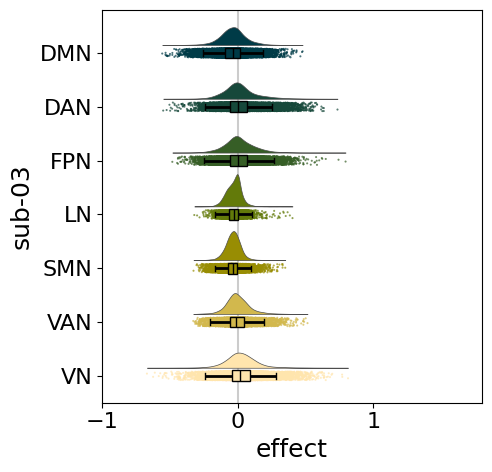

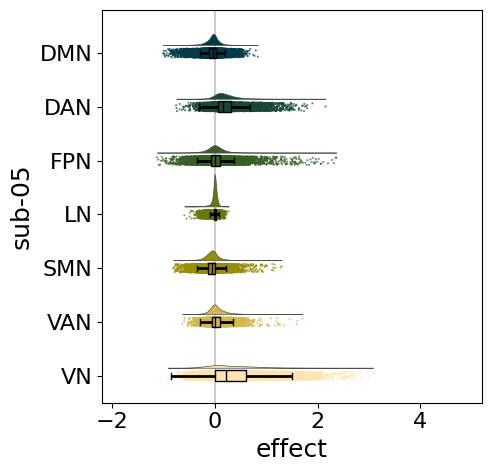

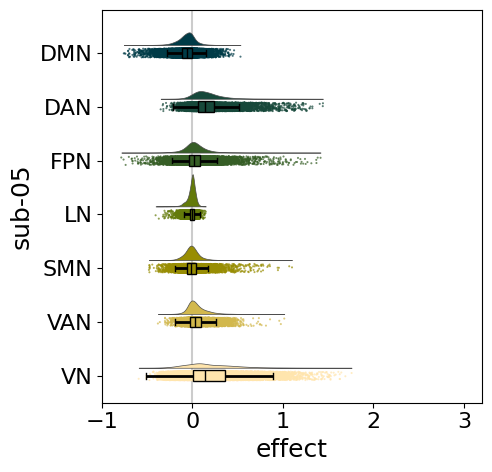

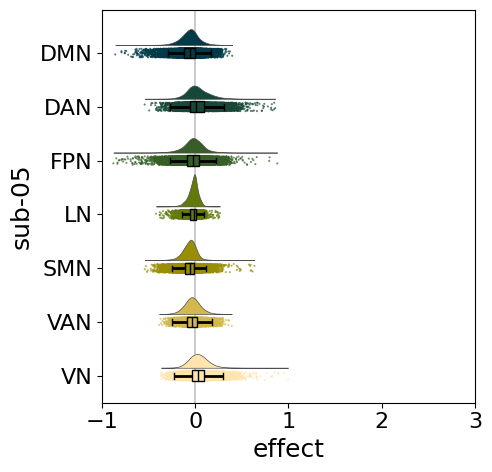

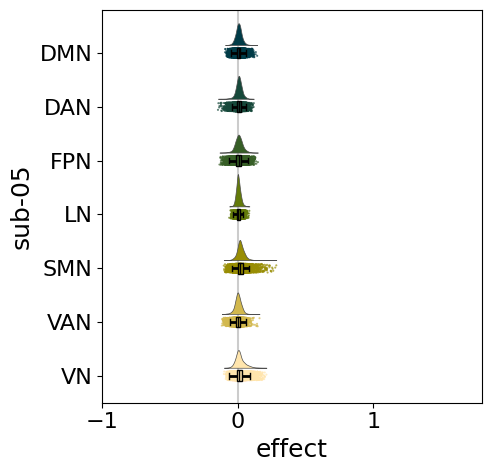

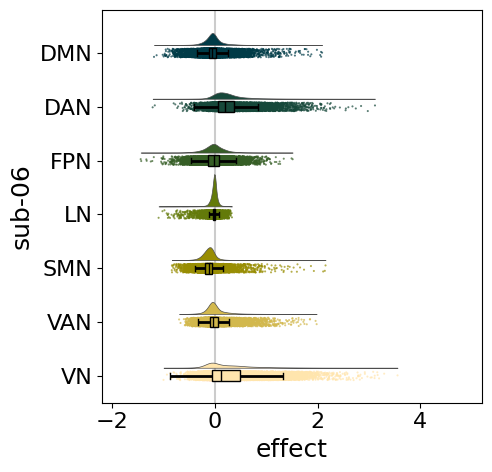

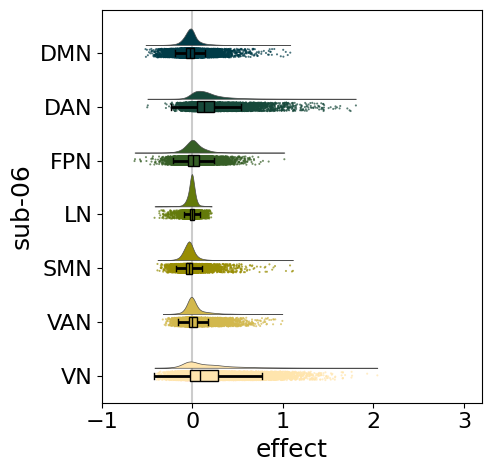

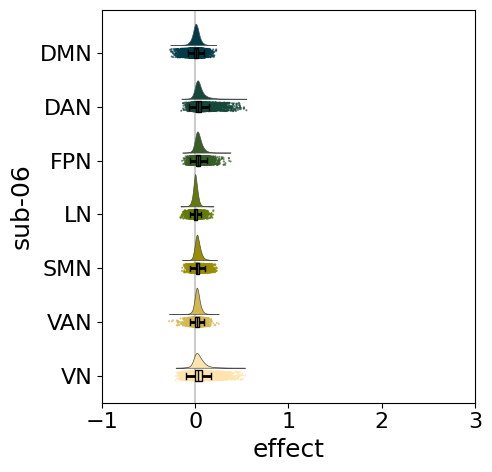

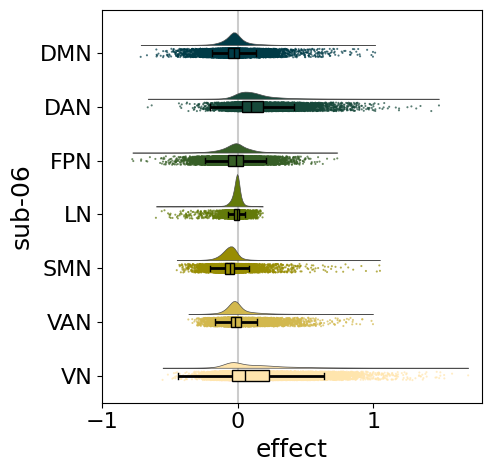

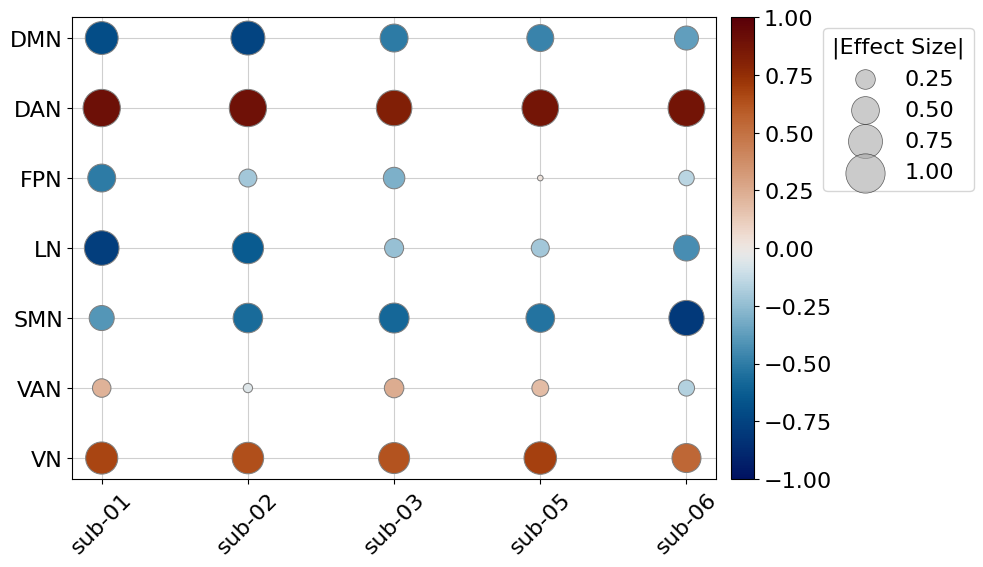

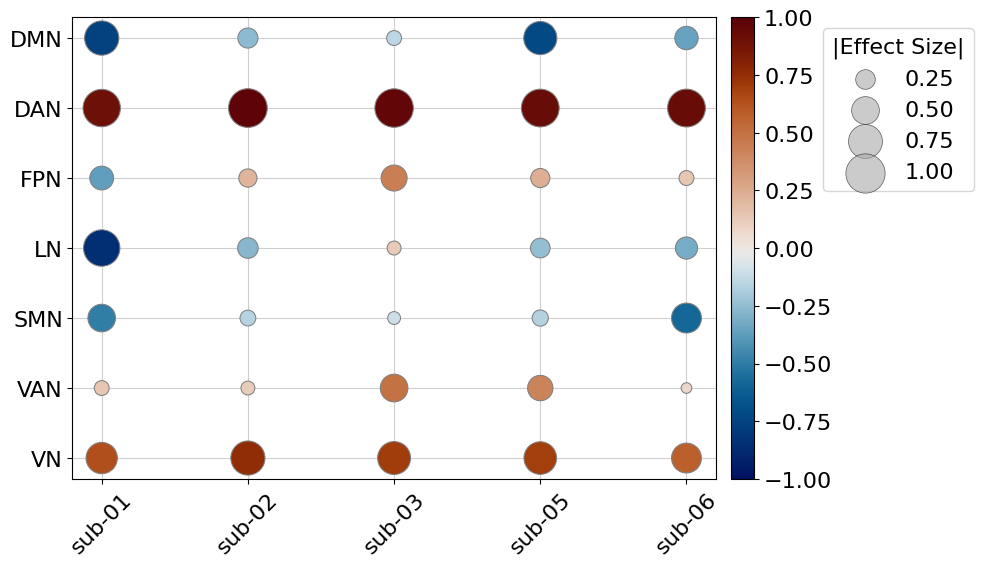

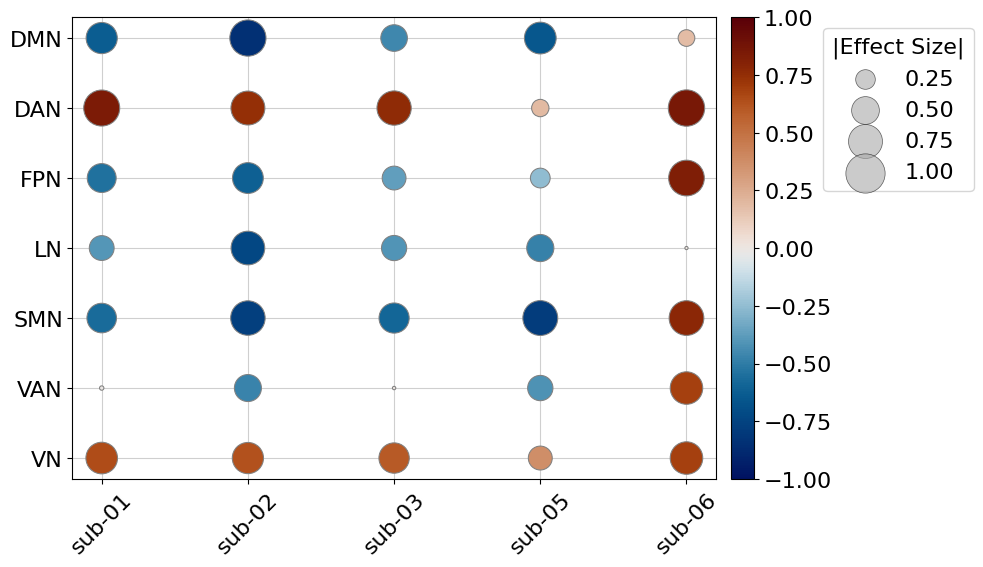

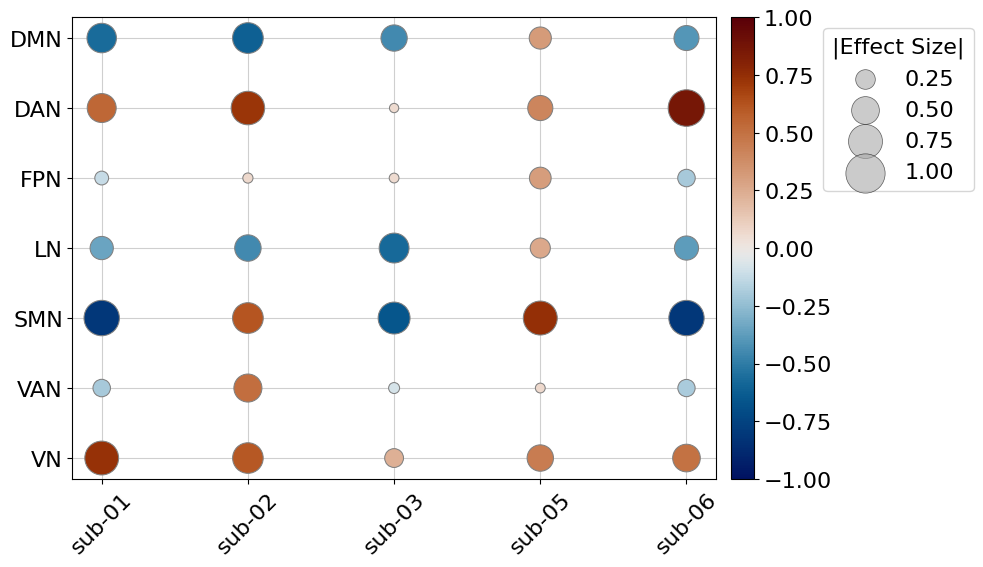

In [22]:
# Define general figure parameters
np.random.seed(42)

SMALL_SIZE = 16
MEDIUM_SIZE = 18
BIGGER_SIZE = 30


plt.rc('font', size=SMALL_SIZE)  # controls default text sizes
plt.rc('axes', titlesize=BIGGER_SIZE)  # fontsize of the axes title
plt.rc('axes', labelsize=MEDIUM_SIZE)  # fontsize of the x and y labels
plt.rc('xtick', labelsize=SMALL_SIZE)  # fontsize of the tick labels
plt.rc('ytick', labelsize=SMALL_SIZE)  # fontsize of the tick labels
plt.rc('legend', fontsize=BIGGER_SIZE)  # legend fontsize
plt.rc('figure', titlesize=BIGGER_SIZE)  # fontsize of the figure title

subjects = layout_input.get_subjects()
contrast_type = ['Stim', 'arousal', 'positiveValence', 'negativeValence']

x_range = {
    'Stim': [-2.2, 5.2],
    'arousal': [-1, 3.2],
    'positiveValence': [-1, 3],
    'negativeValence': [-1, 1.8]
}

df_stat_all = pd.DataFrame()

for subject in subjects:
    print(f'sub-{subject}')
    
    all_files = layout_input.get(subject=subject, suffix='statmap')
    all_files = [f for f in all_files if f'stat-effect' in f.filename and 'desc-denoised' in f.filename]
    for contrast in contrast_type:
        df_effect = pd.DataFrame()
        df_wilcoxon = pd.DataFrame()
        
        print(f'    ... Contrast: {contrast}')
        files = [f for f in all_files if f'contrast-{contrast}_' in f.filename and 'Schaefer2018TianS3NettekovenAsym' in f.filename]
        
        if len(files)>1:
            print(f'More than one file found for sub-{subject} contrast: {contrast}')
            continue
        elif len(files)==0:
            print(f'No file found for sub-{subject} contrast: {contrast}')
            continue
        
        entities = files[0].get_entities()
        
        # Extract betas and compute effect size
        betas, stat, tmp_mask = extract_beta_estimates(files[0].path, 'effect', atlas_path, networks, subject=None, atlas_labels=atlas_labels, effect_size=True)
        stat['subject'] = [f'sub-{subject}']*len(stat)
        stat['contrast'] = [contrast]*len(stat)
        
        df_stat_all = pd.concat([df_stat_all, stat])
        
        # Apply bonferroni corrections
        reject, p_adjusted = multicomp(stat['p_val'], alpha=0.05, method='bonferroni')
        
        print(f'    ... Global mean: {betas['effect'].mean()}')
        
        print('    ... Corrected p values on the Wilcoxon tests')
        print(pd.DataFrame({"network": stat['network'], "pval": stat['p_val'],"pval corr": p_adjusted,"rejected": reject}))
        print('\n')
        
        # Plot beta estimates distributions across networks
        figure_distrib = plot_beta_estimates(betas, stat_type='effect', subject=subject, xlim=x_range[contrast], networks=networks)
        
        output_file = os.path.join(
            output_path,
            f'sub-{subject}',
            f'sub-{subject}_task-{entities["task"]}_space-{entities["space"]}_atlas-Yeo2011_contrast-{contrast}_stat-effect_distribution.svg'
        )
        Path(output_file).parent.mkdir(parents=True, exist_ok=True)
        
        figure_distrib.savefig(
            output_file,
            dpi=600, bbox_inches='tight', transparent=True
        )
        

for contrast in df_stat_all['contrast'].unique():
    # Plot effect size correlogram across networks
    figure_rbc = plot_effect_size(df_stat_all[df_stat_all['contrast']==contrast], networks)
    
    output_file = os.path.join(
        output_path,
        f'task-{entities["task"]}_space-{entities["space"]}_atlas-Yeo2011_contrast-{contrast}_stat-RBC_correlogram.svg'
    )
    Path(output_file).parent.mkdir(parents=True, exist_ok=True)

    figure_rbc.savefig(
        output_file,
        dpi=600, bbox_inches='tight', transparent=True
    )